In [1]:
import numpy as np
import matplotlib.pyplot as plt


In [3]:
from scipy.sparse import csc_matrix
from scipy.sparse.linalg import spsolve


def femcode2dq(p0, f, g):
    """
    Solución de la ecuación de Poisson 1D -u'' = f(x) con u(boundary) = g
    empleando elementos finitos cuadráticos (3 nodos por elemento).
    """
    n = len(p0)  # Número de nodos iniciales
    T = n - 1    # Número de elementos
    dof = 2 * n - 1  # Grados de libertad totales

    # Coordenadas de los nodos
    p = np.zeros(dof)
    p[0::2] = p0
    p[1::2] = 0.5 * (p0[:-1] + p0[1:])  # Nodos medios vectorizados

    # Conectividad de elementos (T x 3)
    t0 = np.arange(0, dof - 1, 2)
    t = np.column_stack([t0, t0 + 1, t0 + 2])

    # Longitud de cada elemento (h_e)
    Area = p0[1:] - p0[:-1]

    # Matriz elemental de referencia (sin dividir entre h_e)
    # Ke_ref / h_e da la matriz elemental real
    Ke_ref = (1.0 / 3.0) * np.array([
        [7.0, -8.0, 1.0],
        [-8.0, 16.0, -8.0],
        [1.0, -8.0, 7.0]
    ])

    # Ensamblado vectorizado de la Matriz de Rigidez K
    rows = np.repeat(t, 3, axis=1).ravel()
    cols = np.tile(t, (1, 3)).ravel()
    data = (Ke_ref[None, :, :] / Area[:, None, None]).ravel()

    K = csc_matrix((data, (rows, cols)), shape=(dof, dof)).tolil()

    # Vector de carga F (Integración Cuadratura Simpson / Simpson-like para f)
    Fe = (Area / 6.0)[:, None] * np.column_stack([f(p[t[:, 0]]), 4.0 * f(p[t[:, 1]]), f(p[t[:, 2]])])
    F = np.bincount(t.ravel(), weights=Fe.ravel(), minlength=dof)

    # Nodos de frontera (izquierdo y derecho)
    b = np.array([0, dof - 1])
    g_val = g(p[b])

    # Aplicación de condiciones de frontera Dirichlet
    F -= K[:, b].dot(g_val)
    F[b] = g_val

    # Imponer 1 en la diagonal y 0 en las filas/columnas de frontera
    for idx, node in enumerate(b):
        K[node, :] = 0.0
        K[:, node] = 0.0
        K[node, node] = 1.0

    # Resolver el sistema lineal disperso
    K = K.tocsc()
    U = spsolve(K, F)

    return U, p

In [9]:
def f(x): return np.pi**2/4*np.sin(np.pi*x/2)
def g(x): return np.sin(np.pi*x/2)

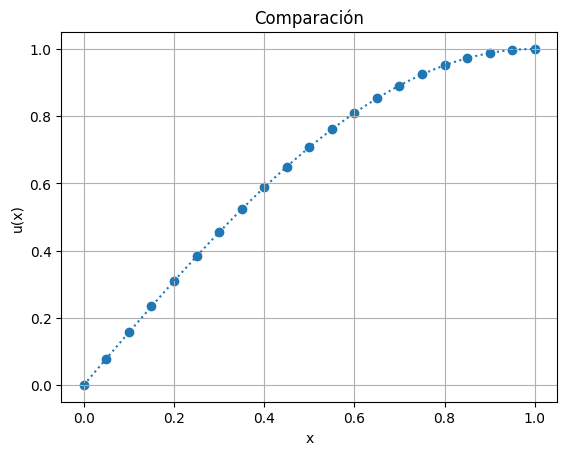

In [10]:
x=np.linspace(0,1,21)

U,p=femcode2dq(x,f,g)

plt.scatter(x,g(x))
plt.plot(p,U,label="aprox", linestyle=':')
#plt.plot(x,np.fabs(U-U_i))

plt.xlabel('x')
plt.ylabel('u(x)')
titulo='Comparación'
plt.title(titulo)

plt.grid()
plt.show()
